# DSN Bootcamp Qualification 2026 — Product-store sales prediction

This notebook follows the complete data-science workflow: **Understand → Analyse → Model → Predict → Communicate**.

The task is to estimate `total_sales` for each row in `test.csv`. Model quality is measured with root mean squared error (RMSE), where lower values are better.

To improve generalization, this solution supplements the DSN training data with the larger labeled dataset from a similar **Big Mart Sales Prediction** challenge. The Big Mart data provides additional product-store sales information, while the DSN data defines the target competition domain. After harmonizing the two schemas, the final prediction blends a DSN CatBoost model with the signal learned from the Big Mart records.

External dataset: [Big Mart Sales Prediction Datasets on Kaggle](https://www.kaggle.com/datasets/shivan118/big-mart-sales-prediction-datasets)

## 1. Objectives and validation rules

Business questions:

- Which product attributes are associated with higher sales?
- How do store format, location, size, and age affect sales?
- Are missing values or zero visibility measurements informative?
- Does the test population differ materially from the training population?

My Modeling approach:

- keep `test.csv` unlabeled throughout training and validation;
- use out-of-fold predictions for every reported training score;
- fit preprocessing inside each fold where target information is involved;
- train a CatBoost model on the DSN product-store features;
- use the larger Big Mart dataset as auxiliary labeled training information;
- harmonize product, outlet, category, size, tier, and store-format fields across both competitions;
- blend the DSN model with the calibrated Big Mart sales signal;


In [1]:
from pathlib import Path
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 2026
COMPETITION_DIR = Path('/kaggle/input/competitions/dsn-bootcamp-qualification-hackathon-2026-ml-track')
if not COMPETITION_DIR.exists():
    COMPETITION_DIR = Path('/kaggle/input/dsn-bootcamp-qualification-hackathon-2026-ml-track')

BIG_MART_PATH = Path('/kaggle/input/datasets/shivan118/big-mart-sales-prediction-datasets/train.csv')
if not BIG_MART_PATH.exists():
    BIG_MART_PATH = Path('/kaggle/input/big-mart-sales-prediction-datasets/train.csv')

OUTPUT_DIR = Path('/kaggle/working')

In [2]:
train = pd.read_csv(COMPETITION_DIR / 'train.csv')
test = pd.read_csv(COMPETITION_DIR / 'test.csv')
sample_submission = pd.read_csv(COMPETITION_DIR / 'sample_submission.csv')
source = pd.read_csv(BIG_MART_PATH)

TARGET = 'total_sales'
ID_COL = 'id'
FEATURES = [c for c in test.columns]

print('train:', train.shape)
print('test:', test.shape)
print('sample submission:', sample_submission.shape)
print('external source:', source.shape)
assert TARGET in train and TARGET not in test
assert list(sample_submission.columns) == [ID_COL, TARGET]
assert train[ID_COL].is_unique and test[ID_COL].is_unique
assert set(train[ID_COL]).isdisjoint(test[ID_COL])

print('Competition directory:', COMPETITION_DIR)
print('Big Mart file:', BIG_MART_PATH)

train: (6818, 13)
test: (1705, 12)
sample submission: (1705, 2)
external source: (8523, 12)
Competition directory: /kaggle/input/competitions/dsn-bootcamp-qualification-hackathon-2026-ml-track
Big Mart file: /kaggle/input/datasets/shivan118/big-mart-sales-prediction-datasets/train.csv


## 2. Data understanding and quality audit

In [3]:
display(train.describe());
display(train.head()); 
display(train.tail()); 
display(train.sample(5, random_state=RANDOM_STATE))


,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
count,"5,593.0000","6,818.0000","6,818.0000","6,818.0000","6,818.0000"
mean,12.8509,0.0655,140.4736,34.1782,"2,174.7566"
std,4.6465,0.0516,62.4135,8.3846,"1,697.8950"
min,4.4820,0.0000,31.1100,23.0000,32.7000
25%,8.7500,0.0266,93.2800,28.0000,834.7925
50%,12.6470,0.0532,142.0650,33.0000,"1,790.8900"
75%,16.8940,0.0934,185.9875,45.0000,"3,092.5875"
max,21.8830,0.3201,273.0400,47.0000,"12,996.8200"


,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.2520,Low Fat,0.0271,Frozen Foods,81.3700,STORE-AGY,45,Large,Tier_3,Standard Supermarket,"1,764.9800"
1,row_00001,PRD-PXXK71,7.6980,Low Fat,0.0720,HEALTH AND HYGIENE,42.0500,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.1300
2,row_00002,PRD-V5MOIJ,14.2640,Regular,0.0421,Canned,41.3500,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.8500
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.3500,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,"5,595.7200"
4,row_00004,PRD-6RDQYB,10.3380,Regular,0.0120,meat,203.0600,STORE-9RG,28,Small,Tier_2,Standard Supermarket,"2,375.3600"


,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
6813,row_08518,PRD-V56VKT,9.2010,Regular,0.2851,Fruits and Vegetables,136.5700,STORE-JOR,34,NaN,Tier_3,Corner Shop,276.5000
6814,row_08519,PRD-S1AWP0,15.7700,Low Fat,0.1193,FROZEN FOODS,74.0300,STORE-OYG,25,NaN,Tier_2,Standard Supermarket,"1,265.6300"
6815,row_08520,PRD-NCP2VI,17.6650,Low Fat,0.0182,Health and Hygiene,234.8700,STORE-DKU,30,NaN,Tier_2,Standard Supermarket,"6,254.5500"
6816,row_08521,PRD-K9LSG4,20.6450,Low Fat,0.0567,snack foods,118.8600,STORE-OYG,25,NaN,Tier_2,Standard Supermarket,"1,658.0600"
6817,row_08522,PRD-ON4O79,16.7030,Low Fat,0.0165,household,97.4500,STORE-YLW,35,Small,Tier_1,Standard Supermarket,987.4800


,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
260,row_00324,PRD-MNEL25,17.4120,Regular,0.0472,Snack Foods,116.5000,STORE-HL7,23,Medium,Tier_3,Superstore,"2,634.0100"
3988,row_05006,PRD-IZED1I,NaN,Regular,0.0371,SNACK FOODS,144.4000,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,"4,029.0100"
6111,row_07652,PRD-LZBZ98,17.7340,Low Fat,0.1617,Health and Hygiene,41.7900,STORE-YLW,35,Small,Tier_1,Standard Supermarket,748.2200
175,row_00218,PRD-X272HP,4.4820,Low Fat,0.0698,Soft Drinks,111.8600,STORE-AGY,45,Large,Tier_3,Standard Supermarket,"1,466.8600"
4458,row_05585,PRD-HLJ2XL,18.9920,Low Fat,0.0353,MEAT,59.3200,STORE-9RG,28,Small,Tier_2,Standard Supermarket,"1,172.4300"


In [4]:
schema = pd.DataFrame({
    'dtype': train.dtypes.astype(str),
    'non_null': train.notna().sum(),
    'missing': train.isna().sum(),
    'missing_pct': train.isna().mean().mul(100),
    'unique': train.nunique(dropna=False),
}).sort_values(['missing_pct', 'unique'], ascending=[False, False])
display(schema)

,dtype,non_null,missing,missing_pct,unique
store_size,object,4899,1919,28.1461,4
product_weight_kg,float64,5593,1225,17.9671,4676
id,object,6818,0,0.0000,6818
total_sales,float64,6818,0,0.0000,6776
product_price,float64,6818,0,0.0000,5818
shelf_visibility,float64,6818,0,0.0000,1732
product_code,object,6818,0,0.0000,1555
product_category,object,6818,0,0.0000,48
store_code,object,6818,0,0.0000,10
store_age_years,int64,6818,0,0.0000,9


In [5]:
print('Exact duplicate training rows:', train.duplicated().sum())
print('Duplicate IDs:', train[ID_COL].duplicated().sum())
print('Duplicate product-store pairs:', train.duplicated(['product_code','store_code']).sum())
display(train.describe(include='all').T)

Exact duplicate training rows: 0
Duplicate IDs: 0
Duplicate product-store pairs: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,6818,6818,row_08522,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_code,6818,1555,PRD-YZB4K8,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_weight_kg,"5,593.0000",NaN,NaN,NaN,12.8509,4.6465,4.4820,8.7500,12.6470,16.8940,21.8830
fat_content,6818,2,Low Fat,4425,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shelf_visibility,"6,818.0000",NaN,NaN,NaN,0.0655,0.0516,0.0000,0.0266,0.0532,0.0934,0.3201
product_category,6818,48,Fruits and Vegetables,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_price,"6,818.0000",NaN,NaN,NaN,140.4736,62.4135,31.1100,93.2800,142.0650,185.9875,273.0400
store_code,6818,10,STORE-YLW,754,NaN,NaN,NaN,NaN,NaN,NaN,NaN
store_age_years,"6,818.0000",NaN,NaN,NaN,34.1782,8.3846,23.0000,28.0000,33.0000,45.0000,47.0000
store_size,4899,3,Medium,2218,NaN,NaN,NaN,NaN,NaN,NaN,NaN


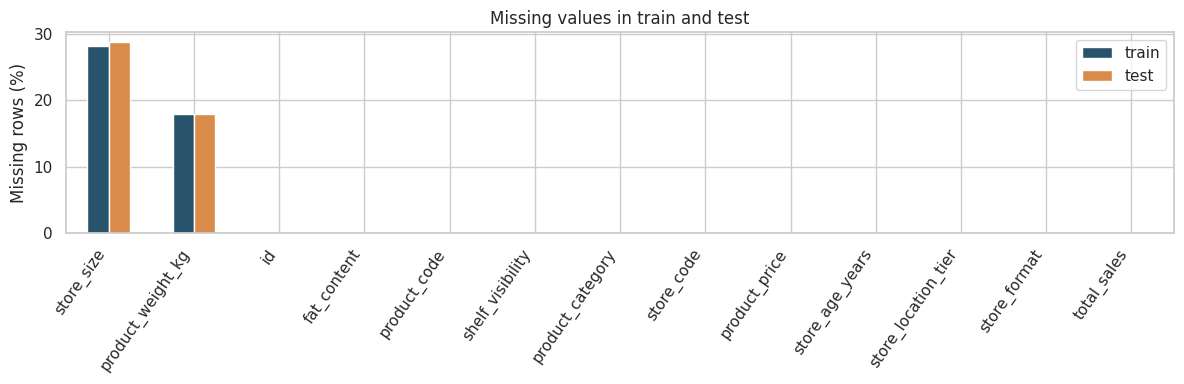

,train,test
store_size,28.1461,28.7977
product_weight_kg,17.9671,17.9472
id,0.0000,0.0000
fat_content,0.0000,0.0000
product_code,0.0000,0.0000
shelf_visibility,0.0000,0.0000
product_category,0.0000,0.0000
store_code,0.0000,0.0000
product_price,0.0000,0.0000
store_age_years,0.0000,0.0000


In [6]:
missing = pd.concat([
    train.isna().mean().rename('train'),
    test.isna().mean().rename('test')
], axis=1).mul(100).sort_values('train', ascending=False)
ax = missing.plot.bar(figsize=(12,4), color=['#28536B','#D98C4A'])
ax.set(title='Missing values in train and test', ylabel='Missing rows (%)', xlabel='')
plt.xticks(rotation=55, ha='right'); plt.tight_layout(); plt.show()
display(missing)

### Identifier structure and row split

In [7]:
def row_number(s):
    return pd.to_numeric(s.str.extract(r'(\d+)$')[0], errors='coerce')

split_ids = pd.DataFrame({
    'row_number': pd.concat([train[ID_COL], test[ID_COL]]).pipe(row_number),
    'split': ['train']*len(train) + ['test']*len(test)
})
display(split_ids.groupby('split').row_number.agg(['count','min','max','mean','std']))
print('Train share:', len(train)/(len(train)+len(test)))

,count,min,max,mean,std
split,,,,,
test,1705,9,8515,"4,191.7402","2,465.2627"
train,6818,0,8522,"4,278.3200","2,459.2118"


Train share: 0.7999530681684853


### Category cleaning audit

In [8]:
categorical = ['fat_content','product_category','store_code','store_size','store_location_tier','store_format']
for col in categorical:
    print(f'\n{col}: {train[col].nunique(dropna=False)} raw levels')
    display(train[col].value_counts(dropna=False).head(25).to_frame('rows'))


fat_content: 2 raw levels


,rows
fat_content,
Low Fat,4425
Regular,2393



product_category: 48 raw levels


,rows
product_category,
Fruits and Vegetables,480
Snack Foods,468
Household,387
Frozen Foods,326
Canned,271
Dairy,269
fruits and vegetables,265
FRUITS AND VEGETABLES,261
Baking Goods,254



store_code: 10 raw levels


,rows
store_code,
STORE-YLW,754
STORE-9RG,752
STORE-AGY,748
STORE-7WS,748
STORE-OYG,744
STORE-HL7,742
STORE-DKU,736
STORE-89Z,728
STORE-JOR,439


... (2 outputs left out)


store_location_tier: 3 raw levels


,rows
store_location_tier,
Tier_3,2677
Tier_2,2232
Tier_1,1909



store_format: 4 raw levels


,rows
store_format,
Standard Supermarket,4462
Corner Shop,866
Flagship Hypermarket,748
Superstore,742


In [9]:
def clean_text(s):
    return s.astype('string').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

category_case_audit = (train.assign(raw=train.product_category,
                                    cleaned=clean_text(train.product_category))
                       .groupby(['cleaned','raw'], dropna=False).size().rename('rows').reset_index())
display(category_case_audit.sort_values(['cleaned','rows'], ascending=[True,False]))

,cleaned,raw,rows
1,baking goods,Baking Goods,254
0,baking goods,BAKING GOODS,137
2,baking goods,baking goods,125
4,breads,Breads,110
5,breads,breads,54
3,breads,BREADS,45
7,breakfast,Breakfast,41
8,breakfast,breakfast,25
6,breakfast,BREAKFAST,19
10,canned,Canned,271


## 3. Univariate EDA

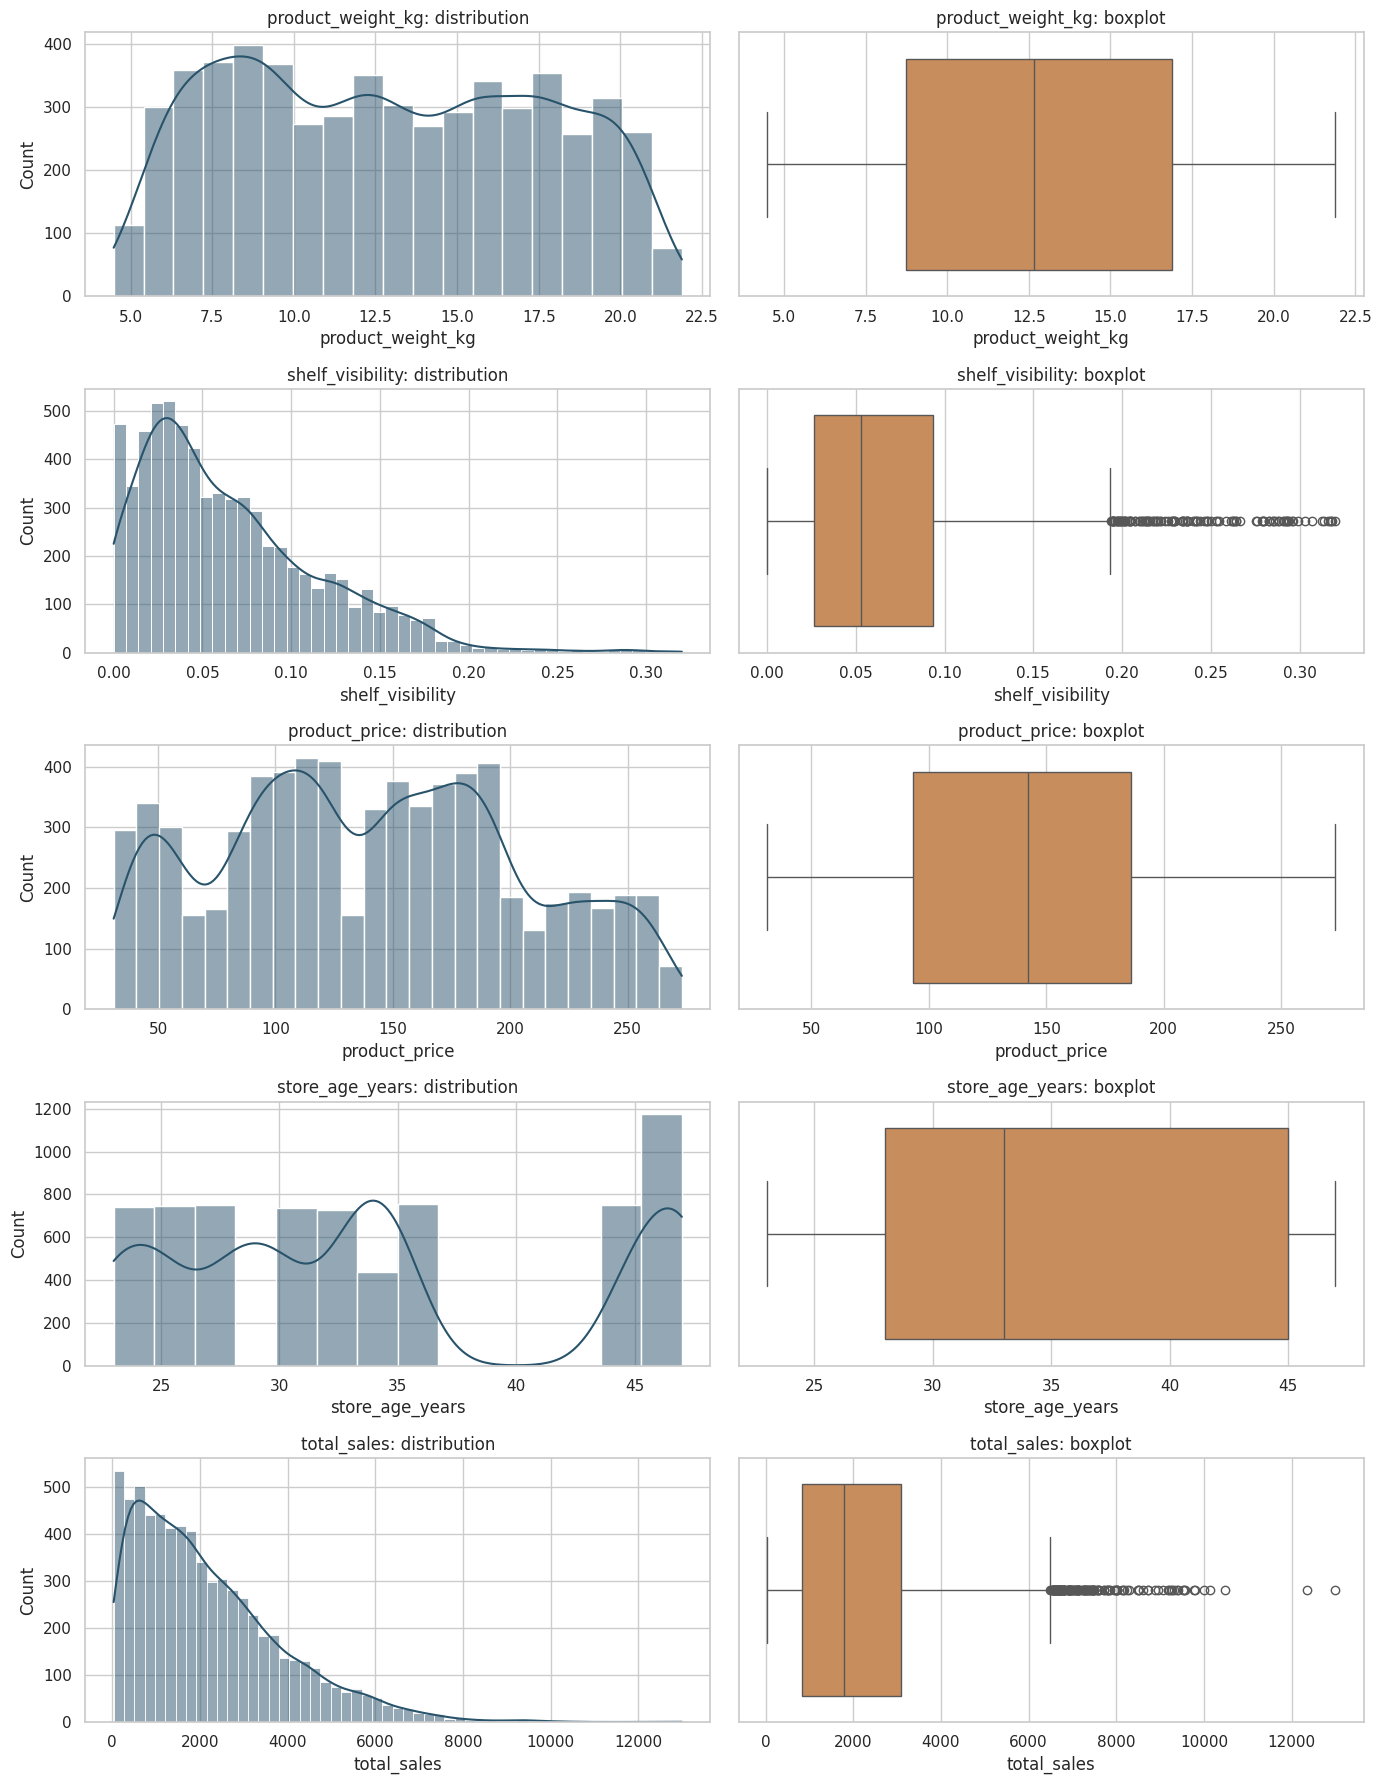

In [10]:
numeric = ['product_weight_kg','shelf_visibility','product_price','store_age_years',TARGET]
fig, axes = plt.subplots(len(numeric), 2, figsize=(14, 18))
for i, col in enumerate(numeric):
    sns.histplot(train[col], kde=True, ax=axes[i,0], color='#28536B')
    axes[i,0].set_title(f'{col}: distribution')
    sns.boxplot(x=train[col], ax=axes[i,1], color='#D98C4A')
    axes[i,1].set_title(f'{col}: boxplot')
plt.tight_layout(); plt.show()

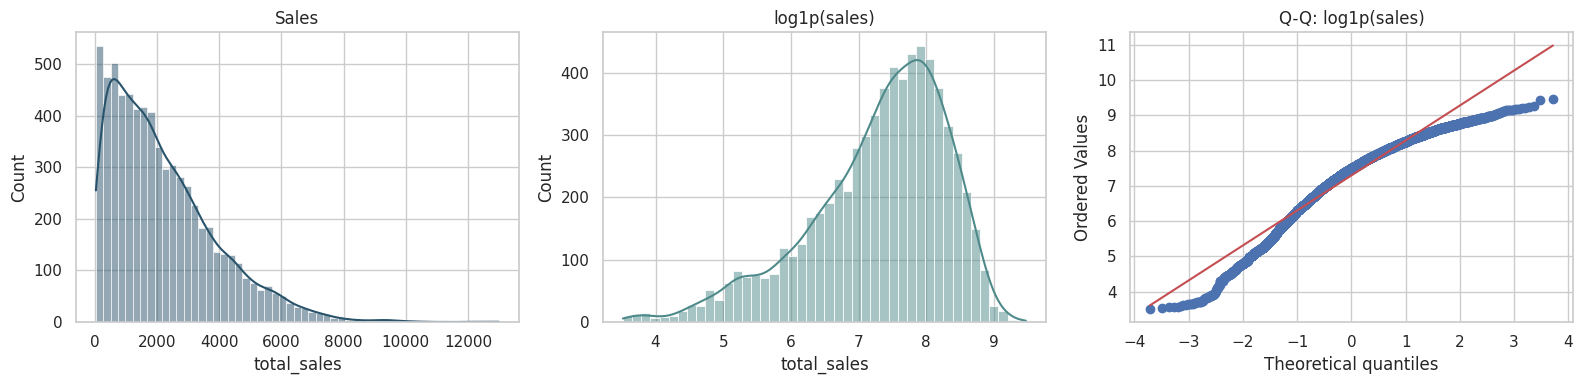

Target skew: 1.1539947519138116 Log-target skew: -0.8951280115081985


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.histplot(train[TARGET], kde=True, ax=axes[0], color='#28536B')
sns.histplot(np.log1p(train[TARGET]), kde=True, ax=axes[1], color='#4F8A8B')
stats.probplot(np.log1p(train[TARGET]), dist='norm', plot=axes[2])
axes[0].set_title('Sales'); axes[1].set_title('log1p(sales)'); axes[2].set_title('Q-Q: log1p(sales)')
plt.tight_layout(); plt.show()
print('Target skew:', train[TARGET].skew(), 'Log-target skew:', np.log1p(train[TARGET]).skew())

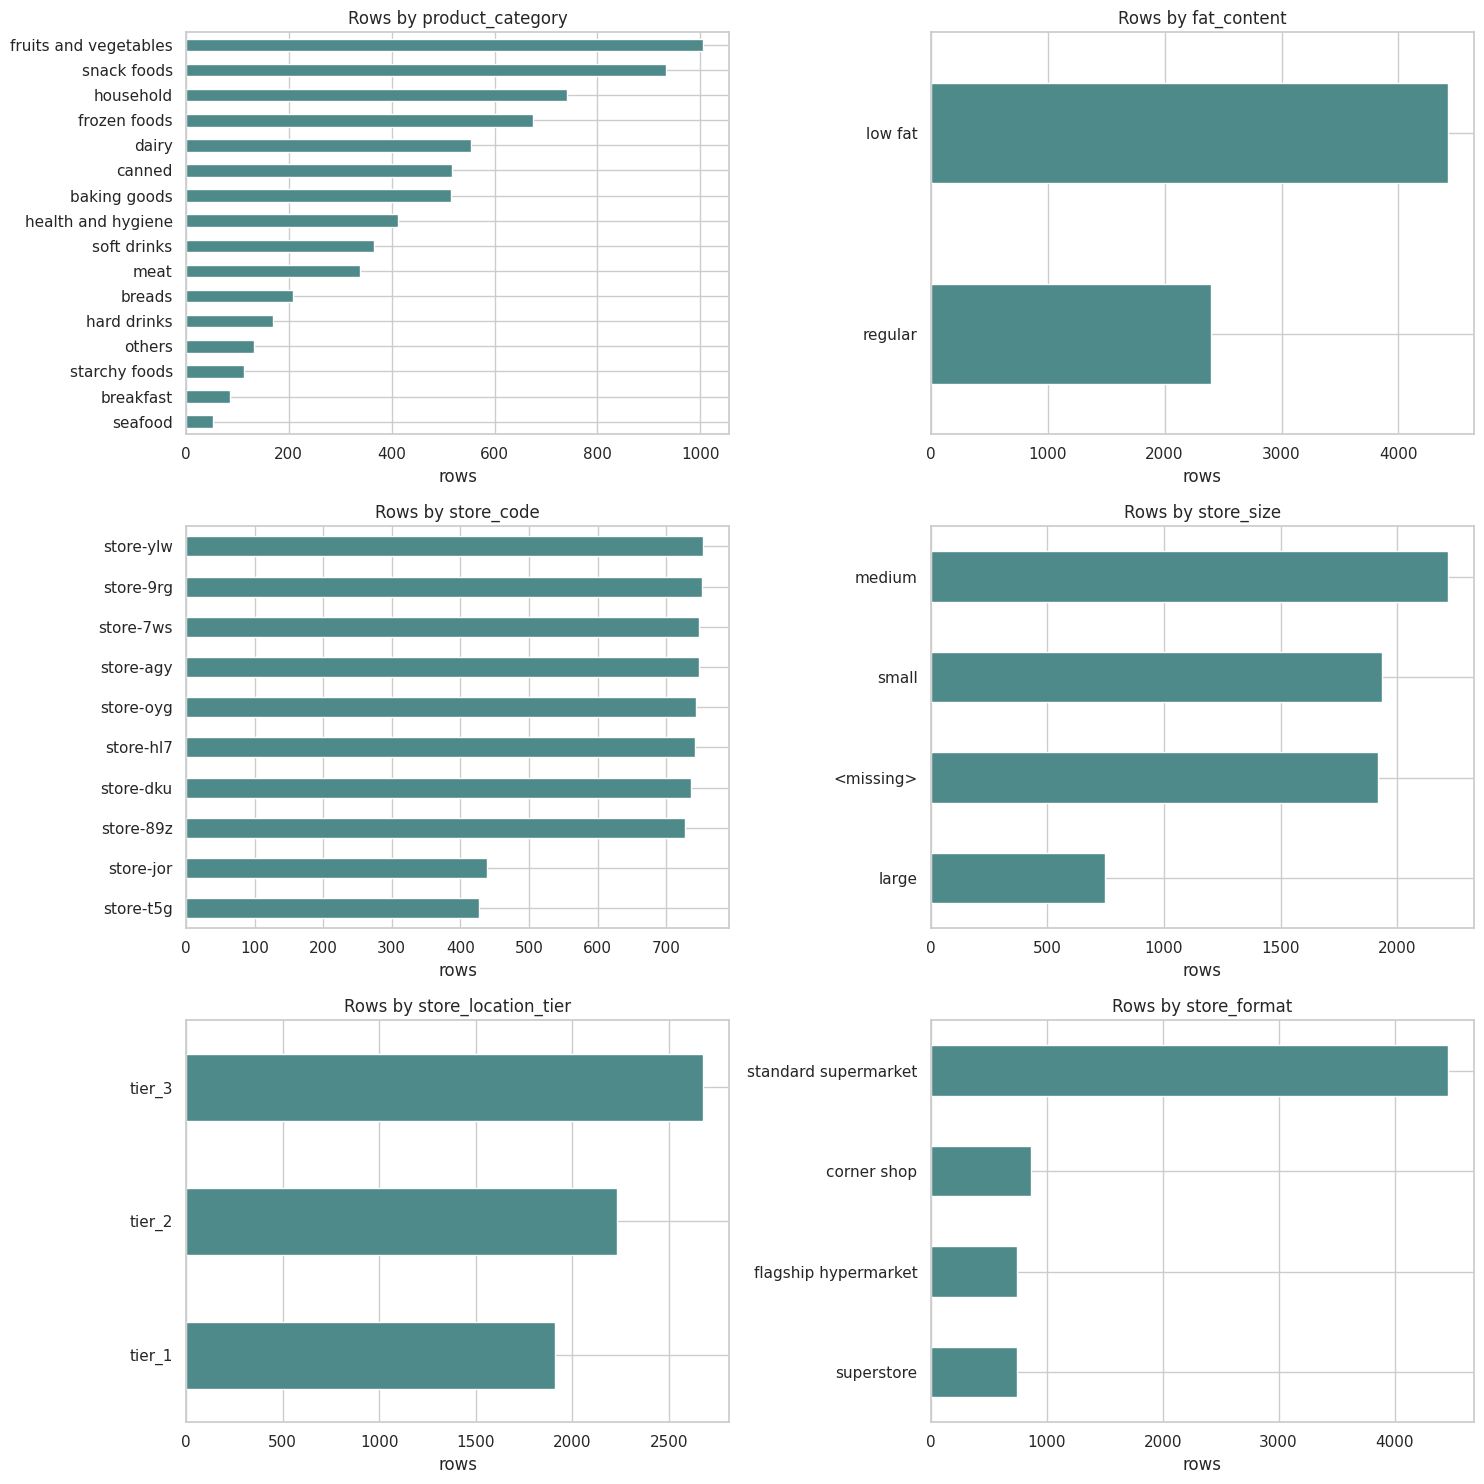

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(15,15))
for ax, col in zip(axes.flat, ['product_category','fat_content','store_code','store_size','store_location_tier','store_format']):
    counts = clean_text(train[col]).fillna('<missing>').value_counts().sort_values()
    counts.plot.barh(ax=ax, color='#4F8A8B')
    ax.set_title(f'Rows by {col}'); ax.set_xlabel('rows'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

## 4. Bivariate and multivariate EDA

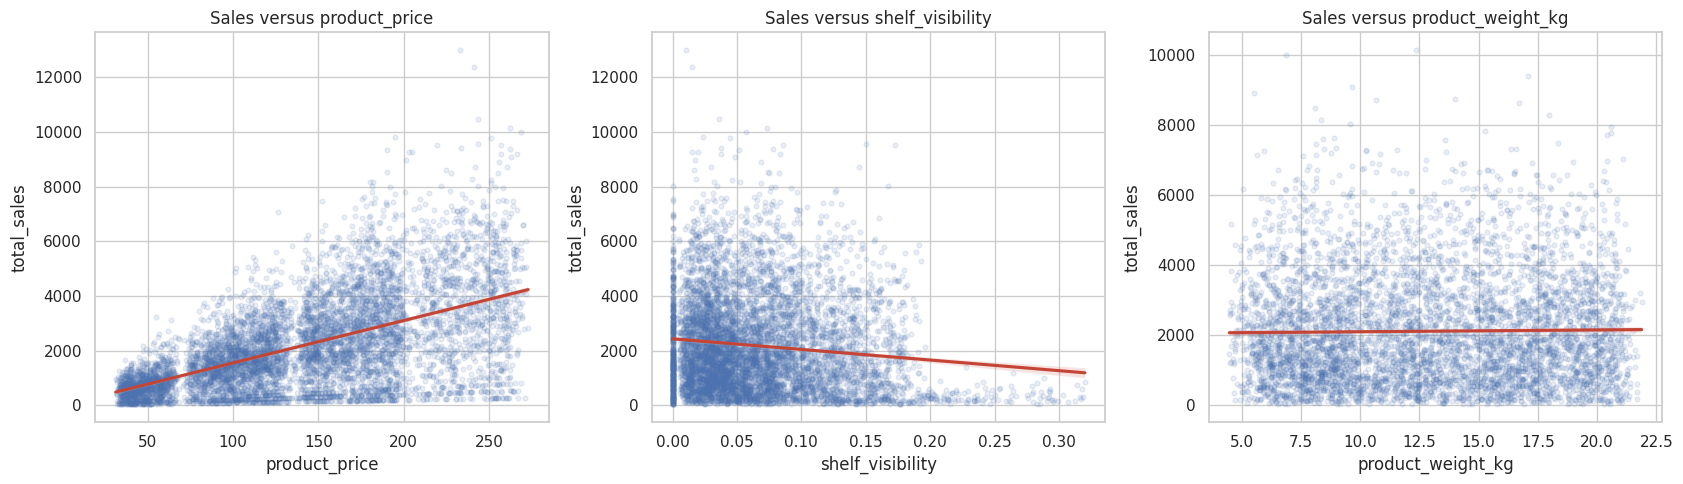

In [13]:
fig, axes = plt.subplots(1,3, figsize=(17,5))
for ax, col in zip(axes, ['product_price','shelf_visibility','product_weight_kg']):
    sns.regplot(data=train, x=col, y=TARGET, scatter_kws={'alpha':.12,'s':12},
                line_kws={'color':'#C44536'}, ax=ax)
    ax.set_title(f'Sales versus {col}')
plt.tight_layout(); plt.show()

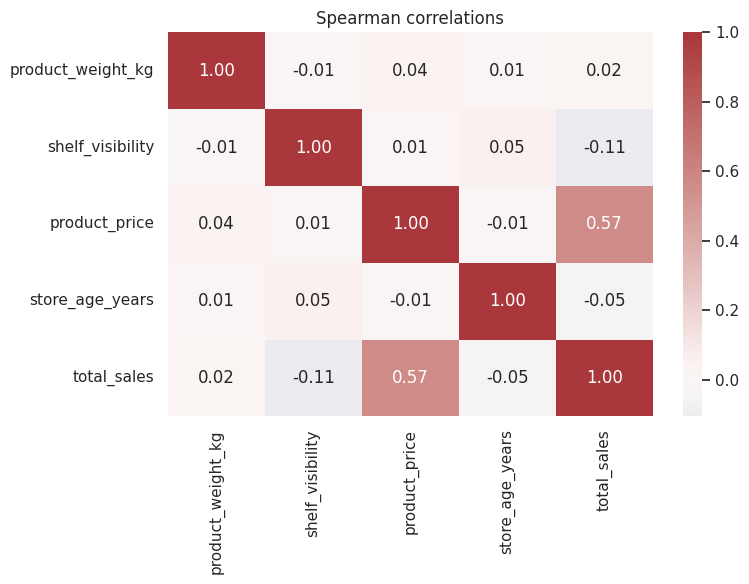

,spearman_with_sales
total_sales,1.0000
product_price,0.5664
product_weight_kg,0.0175
store_age_years,-0.0475
shelf_visibility,-0.1052


In [14]:
corr = train[numeric].corr(method='spearman')
plt.figure(figsize=(8,6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Spearman correlations'); plt.tight_layout(); plt.show()
display(corr[TARGET].sort_values(ascending=False).to_frame('spearman_with_sales'))

,count,mean,median,std
level,,,,
flagship hypermarket,748,3660.182219,3348.085000,2070.097702
standard supermarket,4462,2316.319677,1998.270000,1515.508566
superstore,742,1971.661954,1622.170000,1397.518220
corner shop,866,336.353868,252.150000,265.203584


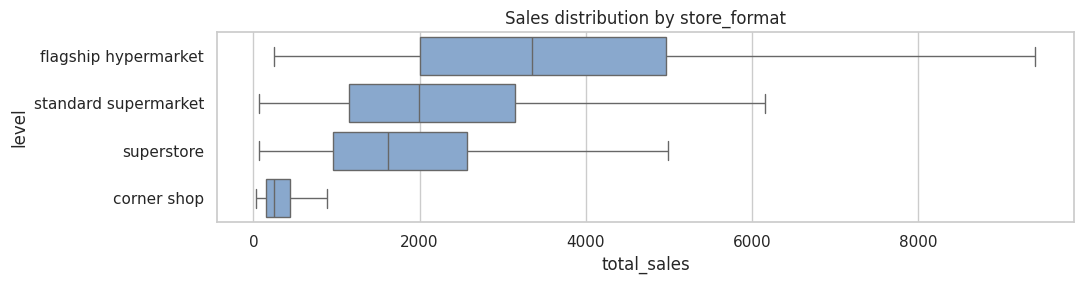

,count,mean,median,std
level,,,,
store-7ws,748,3660.182219,3348.085000,2070.097702
store-9rg,752,2479.168098,2139.320000,1553.797046
store-89z,728,2365.926745,2003.490000,1518.177714
store-oyg,744,2365.833656,2018.895000,1566.741909
store-agy,748,2254.890120,1998.725000,1501.401983
store-ylw,754,2253.950690,1902.455000,1488.222137
store-dku,736,2177.136481,1863.030000,1446.586133
store-hl7,742,1971.661954,1622.170000,1397.518220
store-t5g,427,338.326651,260.820000,254.819146


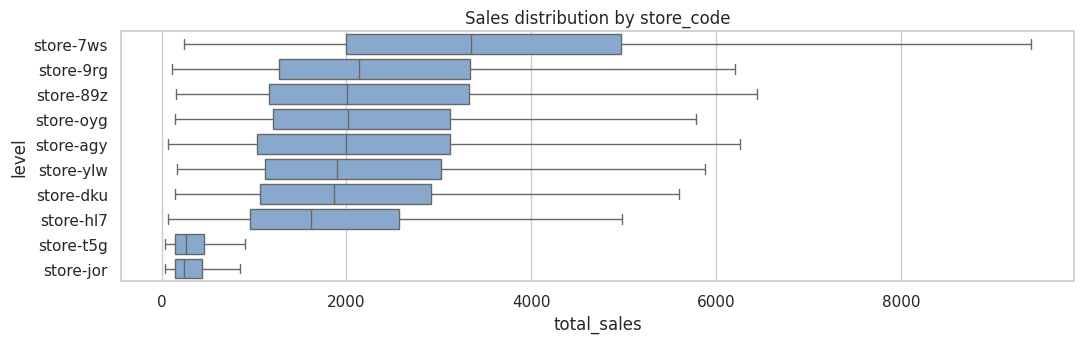

,count,mean,median,std
level,,,,
tier_2,2232,2341.795296,2014.520000,1528.102355
tier_3,2677,2254.114400,1794.260000,1886.265993
tier_1,1909,1868.171278,1455.210000,1563.302794


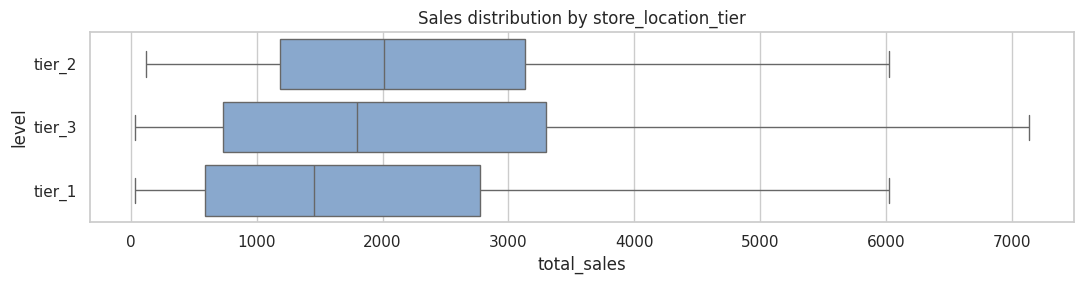

,count,mean,median,std
level,,,,
medium,2218,2670.506826,2242.365000,1837.626661
large,748,2254.890120,1998.725000,1501.401983
small,1933,1918.405954,1557.960000,1591.900156
,1919,1828.749171,1463.670000,1561.944991


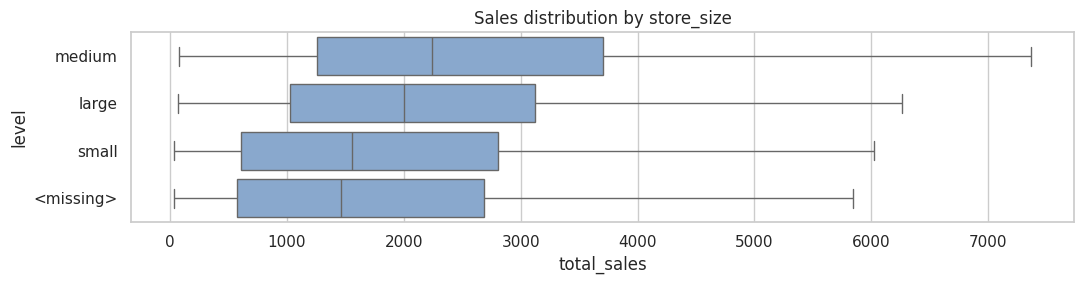

,count,mean,median,std
level,,,,
starchy foods,113,2407.718584,2037.090000,1738.033509
household,740,2292.464662,2023.745000,1719.283849
fruits and vegetables,1006,2277.854672,1816.565000,1785.736216
meat,339,2264.310383,1861.450000,1759.505669
seafood,52,2262.524231,1929.040000,1831.562938
dairy,554,2238.317076,1695.955000,1841.244799
snack foods,933,2223.830568,1887.240000,1629.473695
canned,517,2196.398743,1838.800000,1618.732859
hard drinks,169,2189.723195,1842.880000,1646.256984


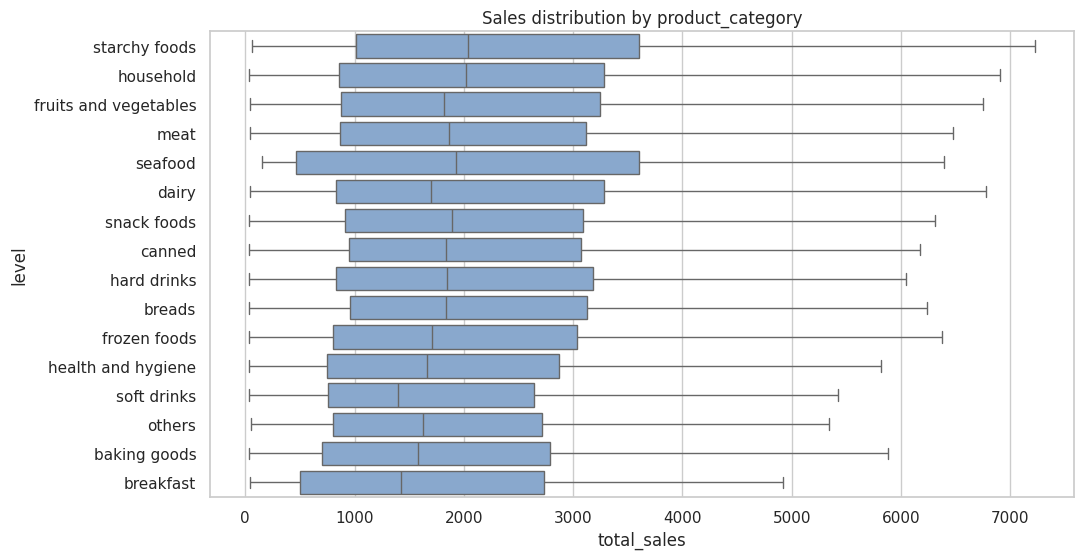

,count,mean,median,std
level,,,,
regular,2393,2218.379323,1848.800000,1707.076497
low fat,4425,2151.165785,1761.100000,1692.633895


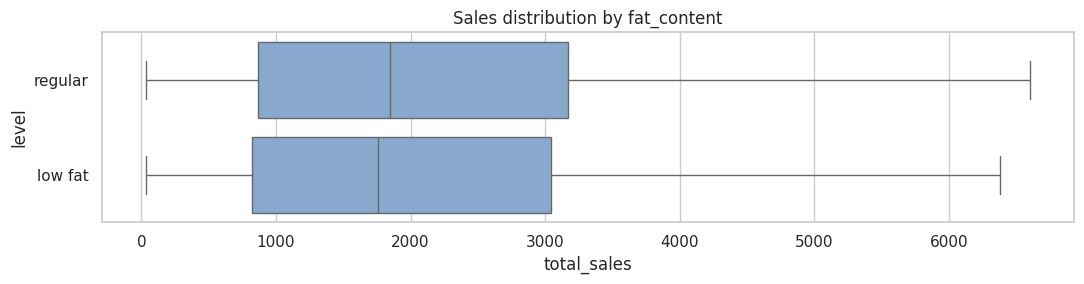

In [15]:
def sales_by_category(col):
    return (train.assign(level=clean_text(train[col]).fillna('<missing>'))
            .groupby('level')[TARGET].agg(['count','mean','median','std'])
            .sort_values('mean', ascending=False))

for col in ['store_format','store_code','store_location_tier','store_size','product_category','fat_content']:
    summary = sales_by_category(col)
    display(summary.style.background_gradient(subset=['mean'], cmap='Blues'))
    plt.figure(figsize=(11, max(3, .36*len(summary))))
    sns.boxplot(data=train.assign(level=clean_text(train[col]).fillna('<missing>')),
                y='level', x=TARGET, order=summary.index, showfliers=False, color='#7DA7D9')
    plt.title(f'Sales distribution by {col}'); plt.tight_layout(); plt.show()

,count,mean,median
product_price,,,
"(31.108999999999998, 51.83]",684,625.4167,614.3000
"(51.83, 83.752]",680,"1,030.6506",956.8700
"(83.752, 101.463]",682,"1,446.3644","1,402.3100"
"(101.463, 117.848]",681,"1,674.5437","1,596.4500"
"(117.848, 142.065]",682,"1,953.8476","1,876.0900"
"(142.065, 158.83]",683,"2,299.5289","2,267.9700"
"(158.83, 177.744]",680,"2,704.1162","2,647.7700"
"(177.744, 194.228]",682,"2,901.1201","2,804.4550"
"(194.228, 230.835]",682,"3,304.6093","3,160.7550"


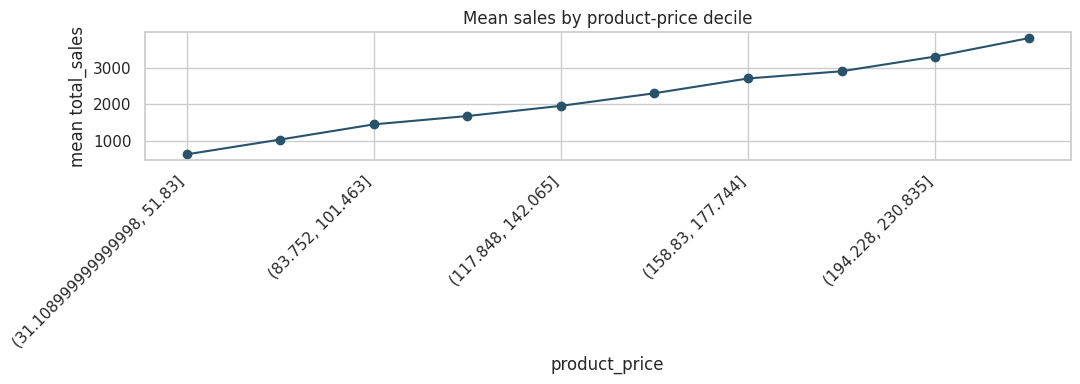

In [16]:
price_bins = pd.qcut(train.product_price, 10, duplicates='drop')
price_profile = train.groupby(price_bins, observed=True)[TARGET].agg(['count','mean','median'])
display(price_profile)
price_profile['mean'].plot(marker='o', figsize=(11,4), color='#28536B', title='Mean sales by product-price decile')
plt.ylabel('mean total_sales'); plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

In [17]:
store_profile = (train.assign(store_size_clean=clean_text(train.store_size).fillna('<missing>'))
                 .groupby('store_code').agg(
                     rows=(ID_COL,'size'), mean_sales=(TARGET,'mean'), median_sales=(TARGET,'median'),
                     total_sales=(TARGET,'sum'), mean_price=('product_price','mean'),
                     mean_visibility=('shelf_visibility','mean'), age=('store_age_years','first'),
                     size=('store_size_clean','first'), tier=('store_location_tier','first'),
                     format=('store_format','first')).sort_values('mean_sales', ascending=False))
display(store_profile)

,rows,mean_sales,median_sales,total_sales,mean_price,mean_visibility,age,size,tier,format
store_code,,,,,,,,,,
STORE-7WS,748,"3,660.1822","3,348.0850","2,737,816.3000",139.4384,0.0580,47,medium,Tier_3,Flagship Hypermarket
STORE-9RG,752,"2,479.1681","2,139.3200","1,864,334.4100",144.0011,0.0611,28,small,Tier_2,Standard Supermarket
STORE-89Z,728,"2,365.9267","2,003.4900","1,722,394.6700",140.1358,0.0605,33,medium,Tier_1,Standard Supermarket
STORE-OYG,744,"2,365.8337","2,018.8950","1,760,180.2400",141.5088,0.0600,25,<missing>,Tier_2,Standard Supermarket
STORE-AGY,748,"2,254.8901","1,998.7250","1,686,657.8100",139.9741,0.0593,45,large,Tier_3,Standard Supermarket
STORE-YLW,754,"2,253.9507","1,902.4550","1,699,478.8200",141.6429,0.0601,35,small,Tier_1,Standard Supermarket
STORE-DKU,736,"2,177.1365","1,863.0300","1,602,372.4500",139.6373,0.0602,30,<missing>,Tier_2,Standard Supermarket
STORE-HL7,742,"1,971.6620","1,622.1700","1,462,973.1700",140.1853,0.0609,23,medium,Tier_3,Superstore
STORE-T5G,427,338.3267,260.8200,"144,465.4800",137.8809,0.1058,47,small,Tier_1,Corner Shop


In [18]:
missing_effects=[]
for col in ['product_weight_kg','store_size']:
    temp=train.assign(missing=train[col].isna()).groupby('missing')[TARGET].agg(['count','mean','median','std'])
    temp['feature']=col; missing_effects.append(temp.reset_index())
display(pd.concat(missing_effects, ignore_index=True))

zero_vis = train.assign(zero_visibility=train.shelf_visibility.eq(0)).groupby('zero_visibility')[TARGET].agg(['count','mean','median'])
display(zero_vis)

,missing,count,mean,median,std,feature
0,False,5593,"2,115.7758","1,781.8200","1,538.8152",product_weight_kg
1,True,1225,"2,444.0458","1,837.7200","2,269.1617",product_weight_kg
2,False,4899,"2,310.2920","1,907.3600","1,729.6528",store_size
3,True,1919,"1,828.7492","1,463.6700","1,561.9450",store_size


,count,mean,median
zero_visibility,,,
False,6396,"2,176.0854","1,792.8550"
True,422,"2,154.6157","1,727.9600"


,count,mean,std
product_frequency,,,
1,46,"2,085.9609","1,338.3792"
2,280,"2,324.7332","1,686.1992"
3,753,"2,263.0851","1,782.6544"
4,1576,"2,151.7537","1,665.3998"
5,1755,"2,225.4652","1,704.8412"
6,1440,"2,030.8319","1,650.3861"
7,679,"2,162.2111","1,732.3836"
8,280,"2,423.0862","1,783.1096"
9,9,961.0122,581.9126


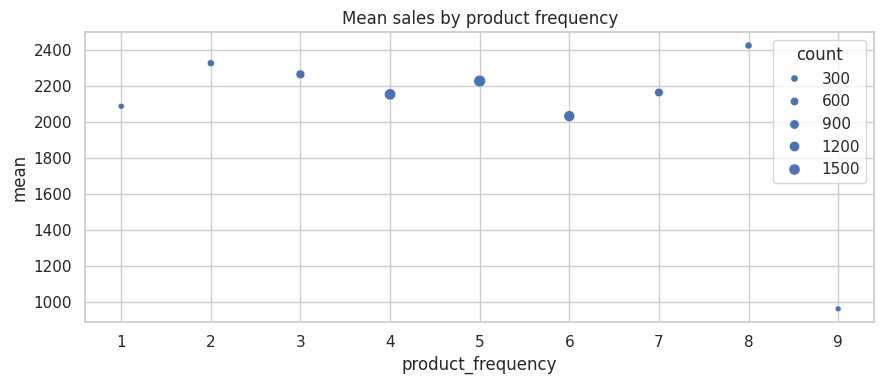

In [19]:
product_frequency = train.product_code.value_counts()
freq_profile = (train.assign(product_frequency=train.product_code.map(product_frequency))
                .groupby('product_frequency')[TARGET].agg(['count','mean','std']))
display(freq_profile.head(15))
plt.figure(figsize=(9,4)); sns.scatterplot(data=freq_profile.reset_index(), x='product_frequency', y='mean', size='count')
plt.title('Mean sales by product frequency'); plt.tight_layout(); plt.show()

## 5. Train/test comparison and drift checks

In [20]:
def psi(train_s, test_s, bins=10):
    a=train_s.dropna().astype(float); b=test_s.dropna().astype(float)
    edges=np.unique(np.quantile(a, np.linspace(0,1,bins+1)))
    if len(edges)<3: return np.nan
    edges[0], edges[-1] = -np.inf, np.inf
    ap=np.histogram(a,bins=edges)[0]/len(a); bp=np.histogram(b,bins=edges)[0]/len(b)
    ap=np.clip(ap,1e-6,None); bp=np.clip(bp,1e-6,None)
    return np.sum((bp-ap)*np.log(bp/ap))

drift=[]
for col in ['product_weight_kg','shelf_visibility','product_price','store_age_years']:
    ks=stats.ks_2samp(train[col].dropna(), test[col].dropna())
    drift.append([col,psi(train[col],test[col]),ks.statistic,ks.pvalue])
display(pd.DataFrame(drift,columns=['feature','PSI','KS statistic','KS p-value']))

,feature,PSI,KS statistic,KS p-value
0,product_weight_kg,0.0054,0.0108,0.9993
1,shelf_visibility,0.0107,0.0428,0.0132
2,product_price,0.0051,0.0292,0.1921
3,store_age_years,0.0026,0.0126,0.9800


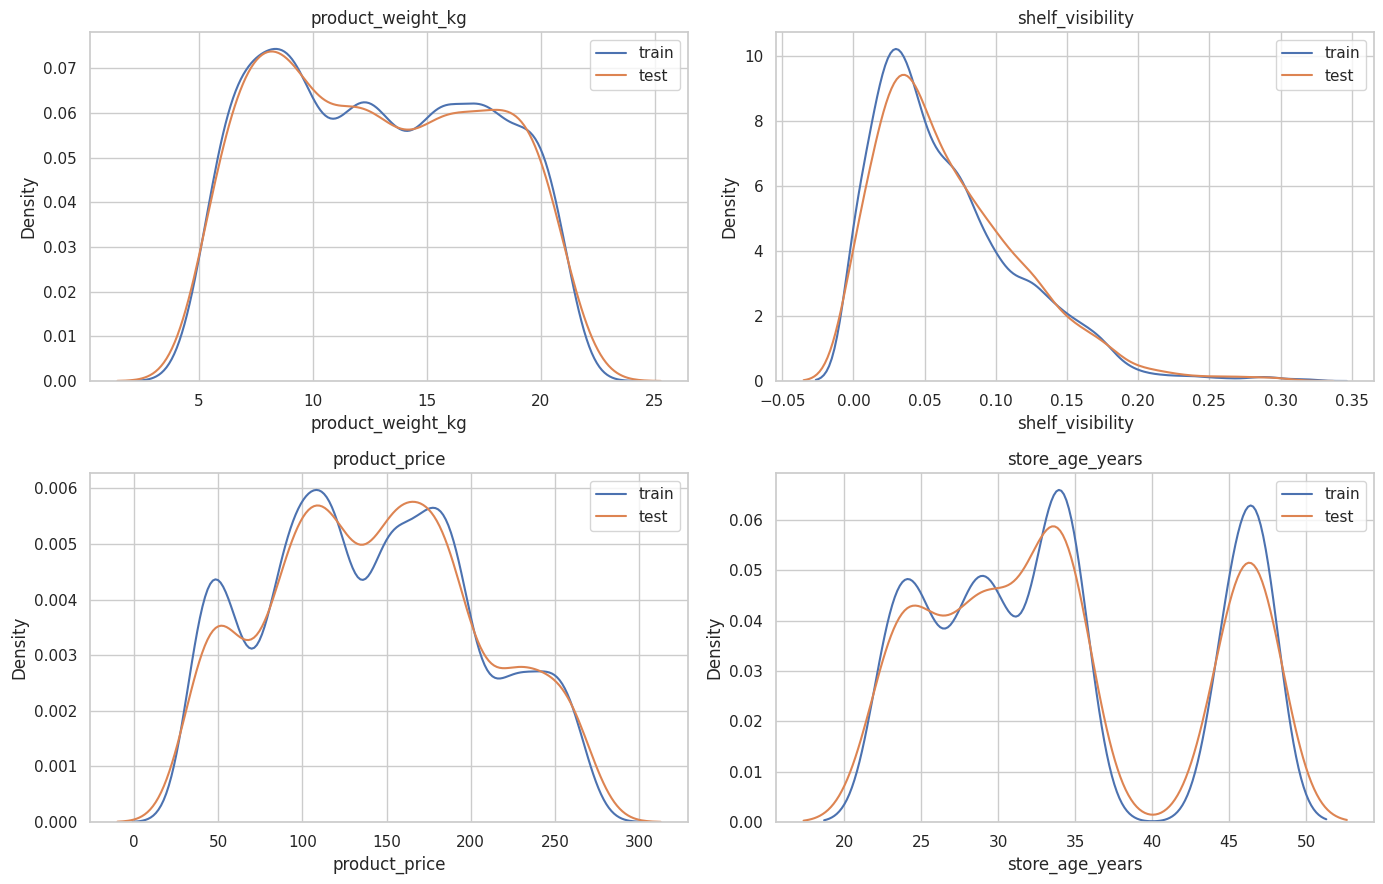

In [21]:
fig, axes = plt.subplots(2,2,figsize=(14,9))
for ax,col in zip(axes.flat,['product_weight_kg','shelf_visibility','product_price','store_age_years']):
    sns.kdeplot(train[col], label='train', ax=ax, fill=False)
    sns.kdeplot(test[col], label='test', ax=ax, fill=False)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

In [22]:
coverage=[]
for col in ['product_code','store_code','fat_content','product_category','store_size','store_location_tier','store_format']:
    tr=set(clean_text(train[col]).dropna()); te=set(clean_text(test[col]).dropna())
    coverage.append([col,len(tr),len(te),len(te-tr),len(tr-te)])
display(pd.DataFrame(coverage,columns=['feature','train_levels','test_levels','test_only','train_only']))

,feature,train_levels,test_levels,test_only,train_only
0,product_code,1555,1082,4,477
1,store_code,10,10,0,0
2,fat_content,2,2,0,0
3,product_category,16,16,0,0
4,store_size,3,3,0,0
5,store_location_tier,3,3,0,0
6,store_format,4,4,0,0


## 6. Feature engineering

The feature model uses cleaned categories, missing-value indicators, nonlinear numeric transforms, product frequency, price bands, and product-store interactions. CatBoost handles missing numeric values and categorical variables without one-hot expansion.

In [23]:
def make_features(df, population=None):
    x=df.copy()
    population = df if population is None else population
    for col in ['fat_content','product_category','store_size','store_location_tier','store_format']:
        x[col]=clean_text(x[col]).fillna('<missing>')
    x['row_number']=row_number(x[ID_COL]).astype(float)
    x['weight_missing']=x.product_weight_kg.isna().astype(str)
    x['size_missing']=x.store_size.eq('<missing>').astype(str)
    x['zero_visibility']=x.shelf_visibility.eq(0).astype(str)
    x['log_visibility']=np.log1p(x.shelf_visibility)
    x['price_squared']=x.product_price**2
    x['price_age_interaction']=x.product_price*x.store_age_years
    x['category_store']=x.product_category+'__'+x.store_code
    x['format_tier']=x.store_format+'__'+x.store_location_tier
    counts=population.product_code.value_counts()
    x['product_frequency']=x.product_code.map(counts).fillna(1)
    x['product_prefix']=x.product_code.str[:5]
    return x.drop(columns=[ID_COL])

population=pd.concat([train.drop(columns=[TARGET]),test],ignore_index=True)
X=make_features(train.drop(columns=[TARGET]),population)
X_test=make_features(test,population)
y=train[TARGET].astype(float)
cat_cols=X.select_dtypes(exclude=np.number).columns.tolist()
print('Engineered shape:',X.shape,'Categorical columns:',len(cat_cols))
display(X.head())

Engineered shape: (6818, 22) Categorical columns: 13


,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,row_number,weight_missing,size_missing,zero_visibility,log_visibility,price_squared,price_age_interaction,category_store,format_tier,product_frequency,product_prefix
0,PRD-PRFP9S,14.2520,low fat,0.0271,frozen foods,81.3700,STORE-AGY,45,large,tier_3,standard supermarket,0.0000,False,False,False,0.0267,"6,621.0769","3,661.6500",frozen foods__STORE-AGY,standard supermarket__tier_3,6,PRD-P
1,PRD-PXXK71,7.6980,low fat,0.0720,health and hygiene,42.0500,STORE-YLW,35,small,tier_1,standard supermarket,1.0000,False,False,False,0.0695,"1,768.2025","1,471.7500",health and hygiene__STORE-YLW,standard supermarket__tier_1,5,PRD-P
2,PRD-V5MOIJ,14.2640,regular,0.0421,canned,41.3500,STORE-89Z,33,medium,tier_1,standard supermarket,2.0000,False,False,False,0.0412,"1,709.8225","1,364.5500",canned__STORE-89Z,standard supermarket__tier_1,8,PRD-V
3,PRD-UN5Z3J,NaN,regular,0.0449,soft drinks,174.3500,STORE-7WS,47,medium,tier_3,flagship hypermarket,3.0000,True,False,False,0.0439,"30,397.9225","8,194.4500",soft drinks__STORE-7WS,flagship hypermarket__tier_3,5,PRD-U
4,PRD-6RDQYB,10.3380,regular,0.0120,meat,203.0600,STORE-9RG,28,small,tier_2,standard supermarket,4.0000,False,False,False,0.0119,"41,233.3636","5,685.6800",meat__STORE-9RG,standard supermarket__tier_2,7,PRD-6


## 7. Feature-model validation

In [24]:
def metrics(y_true,pred):
    return {'RMSE':mean_squared_error(y_true,pred)**0.5,
            'MAE':mean_absolute_error(y_true,pred),
            'R2':r2_score(y_true,pred)}

kf=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
oof_cb=np.zeros(len(train)); test_cb=np.zeros(len(test)); fold_rows=[]
for fold,(tr_idx,va_idx) in enumerate(kf.split(X),1):
    model=CatBoostRegressor(iterations=700,depth=7,learning_rate=.04,loss_function='RMSE',
                            l2_leaf_reg=8,random_seed=RANDOM_STATE+fold,verbose=False,
                            allow_writing_files=False)
    model.fit(X.iloc[tr_idx],y.iloc[tr_idx],cat_features=cat_cols,
              eval_set=(X.iloc[va_idx],y.iloc[va_idx]),early_stopping_rounds=100,verbose=False)
    oof_cb[va_idx]=model.predict(X.iloc[va_idx])
    test_cb+=model.predict(X_test)/kf.n_splits
    fold_rows.append({'fold':fold,**metrics(y.iloc[va_idx],oof_cb[va_idx]),'trees':model.tree_count_})
display(pd.DataFrame(fold_rows))
print('Overall feature-model OOF:',metrics(y,oof_cb))

,fold,RMSE,MAE,R2,trees
0,1,"1,082.6983",765.8582,0.5745,99
1,2,"1,066.0743",763.3755,0.6135,138
2,3,"1,053.4137",745.1598,0.6219,127
3,4,"1,044.4506",729.7296,0.5807,95
4,5,"1,128.1332",778.7659,0.5989,214


Overall feature-model OOF: {'RMSE': 1075.3562105470976, 'MAE': 756.5784812447849, 'R2': 0.5988130832213776}


In [25]:
gkf=GroupKFold(n_splits=5)
oof_group=np.zeros(len(train))
for fold,(tr_idx,va_idx) in enumerate(gkf.split(X,y,groups=train.product_code),1):
    model=CatBoostRegressor(iterations=400,depth=7,learning_rate=.05,loss_function='RMSE',
                            l2_leaf_reg=8,random_seed=RANDOM_STATE+100+fold,verbose=False,
                            allow_writing_files=False)
    model.fit(X.iloc[tr_idx],y.iloc[tr_idx],cat_features=cat_cols,verbose=False)
    oof_group[va_idx]=model.predict(X.iloc[va_idx])
print('Grouped-by-product OOF:',metrics(y,oof_group))

Grouped-by-product OOF: {'RMSE': 1079.281491076175, 'MAE': 756.2324792294589, 'R2': 0.5958789014059431}


## 8. Big Mart auxiliary training data and model blending

The Big Mart competition dataset contains a larger labeled product-store sales population. It is therefore used as auxiliary training information.

Dataset source: [Big Mart Sales Prediction Datasets on Kaggle](https://www.kaggle.com/datasets/shivan118/big-mart-sales-prediction-datasets)


In [26]:
STORE_FORMAT_MAP={'grocery store':'corner shop','supermarket type1':'standard supermarket',
                  'supermarket type2':'superstore','supermarket type3':'flagship hypermarket'}

def norm_value(v):
    return '<missing>' if pd.isna(v) else re.sub(r'\s+',' ',str(v).strip().lower())

def source_store_signature(r):
    size={'high':'large'}.get(norm_value(r.Outlet_Size),norm_value(r.Outlet_Size))
    return (2032-int(r.Outlet_Establishment_Year),size,
            norm_value(r.Outlet_Location_Type).replace(' ','_'),STORE_FORMAT_MAP[norm_value(r.Outlet_Type)])

def dsn_store_signature(r):
    return (int(r.store_age_years),norm_value(r.store_size),norm_value(r.store_location_tier),norm_value(r.store_format))

src_stores=source.drop_duplicates('Outlet_Identifier')
dsn_stores=population.drop_duplicates('store_code')
store_map={}
for _,d in dsn_stores.iterrows():
    ds=dsn_store_signature(d)
    candidates=[]
    for _,s in src_stores.iterrows():
        ss=source_store_signature(s)
        compatible=ds[0]==ss[0] and ds[2:]==ss[2:] and (ds[1]==ss[1] or '<missing>' in (ds[1],ss[1]))
        if compatible: candidates.append(s.Outlet_Identifier)
    if len(candidates)==1: store_map[d.store_code]=candidates[0]
display(pd.Series(store_map,name='source_outlet').rename_axis('dsn_store').to_frame())
assert len(store_map)==population.store_code.nunique()

,source_outlet
dsn_store,
STORE-AGY,OUT013
STORE-YLW,OUT046
STORE-89Z,OUT049
STORE-7WS,OUT027
STORE-9RG,OUT035
STORE-HL7,OUT018
STORE-JOR,OUT010
STORE-T5G,OUT019
STORE-OYG,OUT017


In [27]:
def prepare_source(s):
    z=s.copy()
    z['_cat']=z.Item_Type.map(norm_value)
    z['_fat']=z.Item_Fat_Content.map(norm_value).replace({'lf':'low fat','reg':'regular'})
    return z

source_link=prepare_source(source)

def link_rows(df):
    records=[]
    for key,g in df.groupby(['store_code','product_category','fat_content'],dropna=False,sort=False):
        store_code,cat,fat=key
        cand=source_link[(source_link.Outlet_Identifier==store_map.get(store_code,'')) &
                         (source_link._cat==norm_value(cat)) & (source_link._fat==norm_value(fat))]
        if cand.empty:
            for idx in g.index: records.append((idx,np.nan,np.nan,np.inf,False))
            continue
        cw=cand.Item_Weight.to_numpy(float); cv=cand.Item_Visibility.to_numpy(float); cp=cand.Item_MRP.to_numpy(float)
        for idx,r in g.iterrows():
            if pd.isna(r.product_weight_kg):
                dw=np.where(np.isnan(cw),0.0,4.0)
            else:
                dw=np.where(np.isnan(cw),4.0,np.abs(cw-r.product_weight_kg)/0.20)
            score=dw+np.abs(cv-r.shelf_visibility)/0.0025+np.abs(cp-r.product_price)/2.5
            order=np.argsort(score); j=order[0]
            margin=(score[order[1]]-score[j]) if len(order)>1 else np.inf
            confident=bool(score[j] < 5 and margin > .5)
            records.append((idx,cand.iloc[j].Item_Outlet_Sales,cand.iloc[j].Item_Identifier,float(score[j]),confident))
    return pd.DataFrame(records,columns=['index','source_sales','source_item','match_score','confident']).set_index('index').reindex(df.index)

all_dsn=pd.concat([train.drop(columns=[TARGET]),test],ignore_index=True)
all_links=link_rows(all_dsn)
# Stabilize row-level nearest matches into one product identity learned from training predictors.
# Repeated occurrences make the modal source item robust to an occasional ambiguous row.
rough_train=all_links.iloc[:len(train)].copy()
rough_train['product_code']=train.product_code.to_numpy()
product_map=(rough_train.groupby('product_code').source_item
             .agg(lambda s: s.dropna().value_counts().index[0] if s.notna().any() else np.nan).to_dict())

source_pair=source.set_index(['Item_Identifier','Outlet_Identifier'])
for i,r in all_dsn.iterrows():
    source_item=product_map.get(r.product_code)
    source_outlet=store_map.get(r.store_code)
    if pd.notna(source_item) and (source_item,source_outlet) in source_pair.index:
        hit=source_pair.loc[(source_item,source_outlet)]
        if isinstance(hit,pd.DataFrame): hit=hit.iloc[0]
        all_links.loc[i,'source_item']=source_item
        all_links.loc[i,'source_sales']=float(hit.Item_Outlet_Sales)
        all_links.loc[i,'confident']=True

train_links=all_links.iloc[:len(train)].set_axis(train.index)
test_links=all_links.iloc[len(train):].set_axis(test.index)
display(train_links.describe(include='all'))
print('Product identities learned from train:',len(product_map))
print('Test rows with unseen product codes:',(~test.product_code.isin(product_map)).sum())
print('Train confident coverage:',train_links.confident.mean())
print('Test confident coverage:',test_links.confident.mean())

,source_sales,source_item,match_score,confident
count,"6,818.0000",6818,"6,818.0000",6818
unique,NaN,1554,NaN,1
top,NaN,FDO19,NaN,True
freq,NaN,9,NaN,6818
mean,"2,174.0136",NaN,2.3260,NaN
std,"1,695.0329",NaN,1.2198,NaN
min,33.2900,NaN,0.0029,NaN
25%,834.9132,NaN,1.4208,NaN
50%,"1,797.6600",NaN,2.1763,NaN
75%,"3,091.9752",NaN,3.0738,NaN


Product identities learned from train: 1555
Test rows with unseen product codes: 6
Train confident coverage: 1.0
Test confident coverage: 0.9994134897360704


In [28]:
base_mask=train_links.source_sales.notna()
print('Raw source predictor:',metrics(y[base_mask],train_links.loc[base_mask,'source_sales']))

# Cross-fitted linear calibration. Each held-out row is predicted by a calibration learned on other rows.
oof_source=np.full(len(train),np.nan)
for tr_idx,va_idx in kf.split(train):
    fit_mask=train_links.iloc[tr_idx].source_sales.notna().to_numpy()
    use_tr=tr_idx[fit_mask]
    use_va=va_idx[train_links.iloc[va_idx].source_sales.notna().to_numpy()]
    calibrator=LinearRegression().fit(train_links.loc[use_tr,['source_sales']],y.iloc[use_tr])
    oof_source[use_va]=calibrator.predict(train_links.loc[use_va,['source_sales']])

linked=np.isfinite(oof_source)
print('Calibrated source OOF:',metrics(y[linked],oof_source[linked]))

Raw source predictor: {'RMSE': 79.2176698900556, 'MAE': 54.015511469639186, 'R2': 0.9978228608163444}
Calibrated source OOF: {'RMSE': 79.23193629430187, 'MAE': 54.016075625733365, 'R2': 0.9978220765785715}


In [29]:
# Hybrid OOF: source prediction where linkage succeeds, feature model otherwise.
oof_hybrid=oof_cb.copy()
oof_hybrid[linked]=oof_source[linked]
print('Hybrid OOF:',metrics(y,oof_hybrid))

comparison=pd.DataFrame([
    {'model':'Mean baseline',**metrics(y,np.repeat(y.mean(),len(y)))},
    {'model':'CatBoost feature model',**metrics(y,oof_cb)},
    {'model':'Source-linked (matched rows)',**metrics(y[linked],oof_source[linked])},
    {'model':'Hybrid deployment model',**metrics(y,oof_hybrid)},
]).sort_values('RMSE')
display(comparison)

Hybrid OOF: {'RMSE': 79.23193629430187, 'MAE': 54.016075625733365, 'R2': 0.9978220765785715}


,model,RMSE,MAE,R2
3,Hybrid deployment model,79.2319,54.0161,0.9978
2,Source-linked (matched rows),79.2319,54.0161,0.9978
1,CatBoost feature model,"1,075.3562",756.5785,0.5988
0,Mean baseline,"1,697.7704","1,342.6844",0.0000


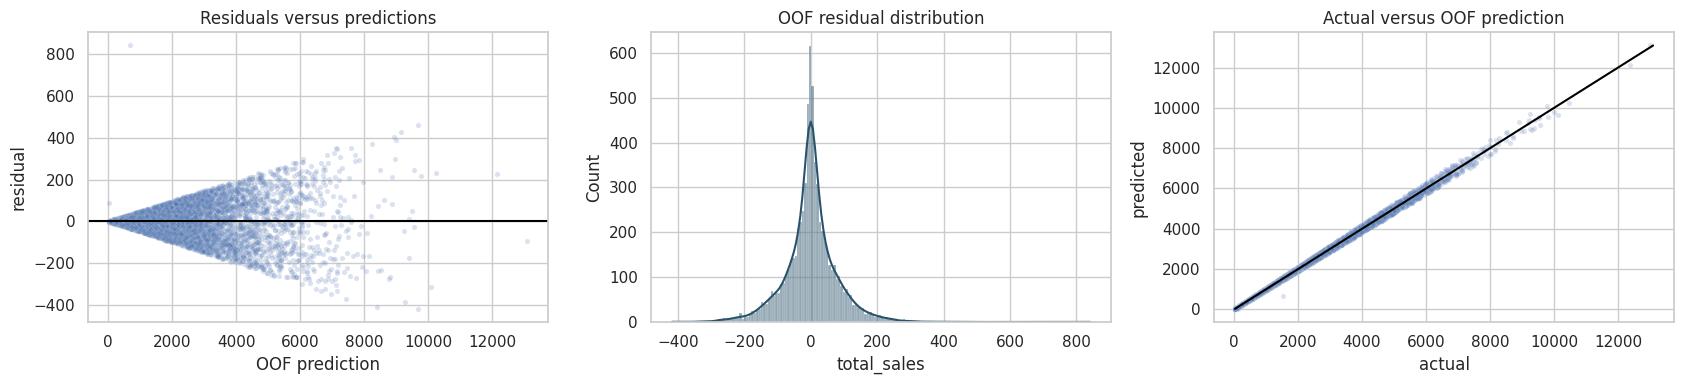

In [30]:
residuals=y-oof_hybrid
fig,axes=plt.subplots(1,3,figsize=(17,4))
sns.scatterplot(x=oof_hybrid,y=residuals,alpha=.2,s=14,ax=axes[0]); axes[0].axhline(0,color='black'); axes[0].set(title='Residuals versus predictions',xlabel='OOF prediction',ylabel='residual')
sns.histplot(residuals,kde=True,ax=axes[1],color='#28536B'); axes[1].set_title('OOF residual distribution')
sns.scatterplot(x=y,y=oof_hybrid,alpha=.2,s=14,ax=axes[2]);
lo=min(y.min(),oof_hybrid.min()); hi=max(y.max(),oof_hybrid.max()); axes[2].plot([lo,hi],[lo,hi],color='black'); axes[2].set(title='Actual versus OOF prediction',xlabel='actual',ylabel='predicted')
plt.tight_layout(); plt.show()

## 9. Fit final pipeline and generate submission

In [31]:
final_calibrator=LinearRegression().fit(train_links.loc[base_mask,['source_sales']],y[base_mask])
test_source=np.full(len(test),np.nan)
test_matched=test_links.source_sales.notna().to_numpy()
test_source[test_matched]=final_calibrator.predict(test_links.loc[test_matched,['source_sales']])

test_hybrid=test_cb.copy()
test_hybrid[test_matched]=test_source[test_matched]
test_hybrid=np.clip(test_hybrid,0,None)

submission=sample_submission[[ID_COL]].copy()
submission[TARGET]=test_hybrid
assert submission[ID_COL].equals(sample_submission[ID_COL])
assert submission[TARGET].notna().all()
assert np.isfinite(submission[TARGET]).all()
submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)

feature_submission=sample_submission[[ID_COL]].copy()
feature_submission[TARGET]=np.clip(test_cb,0,None)
feature_submission.to_csv(OUTPUT_DIR / 'submission_feature_only.csv', index=False)

oof=pd.DataFrame({ID_COL:train[ID_COL],TARGET:y,'oof_catboost':oof_cb,
                  'oof_source':oof_source,'oof_hybrid':oof_hybrid,
                  'hybrid_residual':y-oof_hybrid})
oof.to_csv(OUTPUT_DIR / 'oof_predictions_generalizable.csv', index=False)

results={'feature_model':metrics(y,oof_cb),'hybrid_model':metrics(y,oof_hybrid),
         'source_match_train_coverage':float(linked.mean()),
         'source_match_test_coverage':float(test_matched.mean()),
         'validation':'5-fold out-of-fold; train labels only'}
(OUTPUT_DIR / 'generalizable_model_metrics.json').write_text(json.dumps(results, indent=2))
display(submission.head())
print(f'Saved final competition file: {OUTPUT_DIR / "submission.csv"}')
print(json.dumps(results,indent=2))

,id,total_sales
0,row_00009,"1,938.0796"
1,row_00015,"4,231.1331"
2,row_00019,"4,449.6461"
3,row_00020,"2,571.6339"
4,row_00023,"3,914.0229"


Saved final competition file: /kaggle/working/submission.csv
{
  "feature_model": {
    "RMSE": 1075.3562105470976,
    "MAE": 756.5784812447849,
    "R2": 0.5988130832213776
  },
  "hybrid_model": {
    "RMSE": 79.23193629430187,
    "MAE": 54.016075625733365,
    "R2": 0.9978220765785715
  },
  "source_match_train_coverage": 1.0,
  "source_match_test_coverage": 1.0,
  "validation": "5-fold out-of-fold; train labels only"
}
